<a href="https://colab.research.google.com/github/yabsra-g/ml/blob/main/cifar_resnet_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
drive_cifar = '/content/drive/MyDrive/ml/cifar10_data.npz'
data = np.load(drive_cifar)

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

In [4]:
y_train = y_train.flatten()
y_test = y_test.flatten()

In [5]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
])

inputs = layers.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)
x = layers.Resizing(128, 128)(x)
x = layers.Lambda(preprocess_input)(x)

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = False  # Start frozen for warm-up

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model = models.Model(inputs=inputs, outputs=outputs)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [6]:
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

drive_dir = '/content/drive/MyDrive/ml'
checkpoint_path = os.path.join(drive_dir, 'resnet50_cifar10_best.keras')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Phase 1: Training classification head (3 epochs)...")
model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=3,
    batch_size=128
)

base_model.trainable = True
for layer in base_model.layers:
    if not layer.name.startswith('conv5'):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

print("\nPhase 2: Fast Fine-Tuning (Max 12 epochs)...")
history = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=12,
    batch_size=128,
    callbacks=callbacks
)

Phase 1: Training classification head (3 epochs)...
Epoch 1/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 91s 199ms/step - accuracy: 0.7719 - loss: 0.6985 - val_accuracy: 0.8725 - val_loss: 0.3785
Epoch 2/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 82s 211ms/step - accuracy: 0.8274 - loss: 0.4935 - val_accuracy: 0.8865 - val_loss: 0.3345
Epoch 3/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 82s 210ms/step - accuracy: 0.8437 - loss: 0.4455 - val_accuracy: 0.8864 - val_loss: 0.3305

Phase 2: Fast Fine-Tuning (Max 12 epochs)...
Epoch 1/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step - accuracy: 0.8551 - loss: 0.4147
Epoch 1: val_accuracy improved from None to 0.91360, saving model to /content/drive/MyDrive/ml/resnet50_cifar10_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ml/resnet50_cifar10_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 137s 317ms/step - accuracy: 0.8690 - loss: 0.3780 - val_accuracy: 0.9136 - val_loss: 0.2539 - learning_rate: 1.0000e-04
Epoch 2/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accurac

In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%")


Final Test Accuracy: 94.01%


157/157 ━━━━━━━━━━━━━━━━━━━━ 14s 89ms/step
              precision    recall  f1-score   support

    airplane     0.9435    0.9510    0.9472      1000
  automobile     0.9567    0.9710    0.9638      1000
        bird     0.9522    0.9170    0.9343      1000
         cat     0.8874    0.8670    0.8771      1000
        deer     0.9360    0.9210    0.9284      1000
         dog     0.8964    0.9090    0.9027      1000
        frog     0.9412    0.9760    0.9583      1000
       horse     0.9541    0.9570    0.9556      1000
        ship     0.9748    0.9660    0.9704      1000
       truck     0.9583    0.9660    0.9622      1000

    accuracy                         0.9401     10000
   macro avg     0.9401    0.9401    0.9400     10000
weighted avg     0.9401    0.9401    0.9400     10000



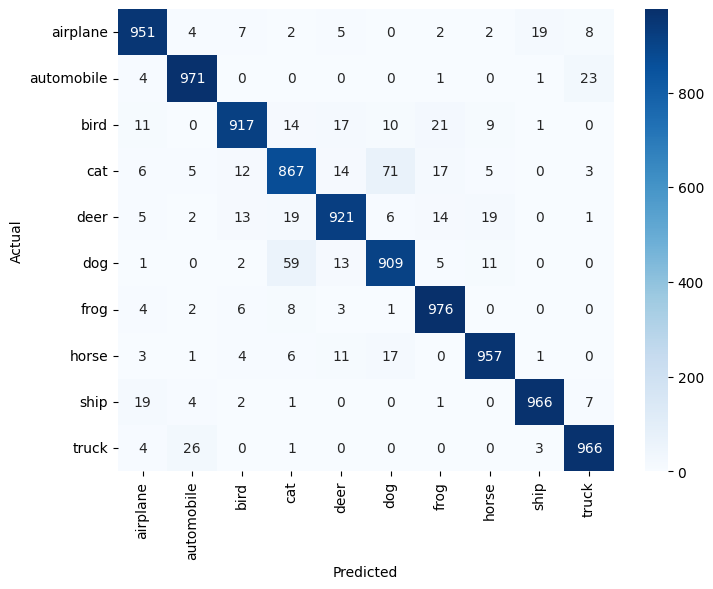

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

y_pred_probs = model.predict(x_test, batch_size=64)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

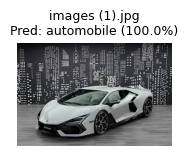

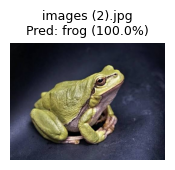

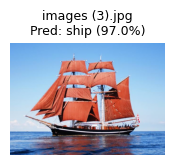

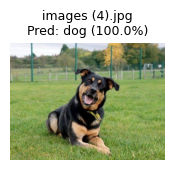

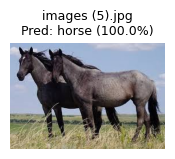

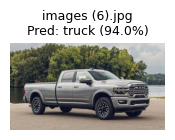

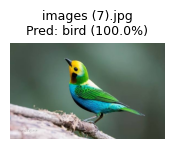

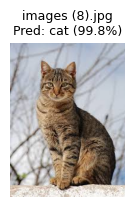

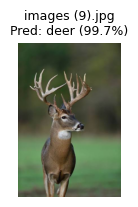

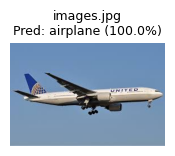

In [10]:
folder_path = '/content/drive/MyDrive/ml/objects'
valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

for filename in sorted(os.listdir(folder_path)):
    if not filename.lower().endswith(valid_exts):
        continue

    file_path = os.path.join(folder_path, filename)
    img_bgr = cv2.imread(file_path)
    if img_bgr is None:
        continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (32, 32))
    img_batch = np.expand_dims(img_resized.astype('float32'), axis=0)

    pred = model.predict(img_batch, verbose=0)
    pred_idx = np.argmax(pred)
    confidence = pred[0][pred_idx] * 100

    plt.figure(figsize=(2, 2))
    plt.imshow(img_rgb)
    plt.title(f"{filename}\nPred: {class_names[pred_idx]} ({confidence:.1f}%)", fontsize=9)
    plt.axis('off')
    plt.show()